# Prototype De-stacking

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import galsim
import ultranest as un
from colossus.halo import profile_nfw
from colossus.cosmology import cosmology as colossus_cosmology
import astropy.units as u
from astropy.cosmology import Planck18 
from astropy import constants
from scipy import integrate

In [2]:
Mhalo = 1e14
conc = 5.
zhalo = .3
OmegaM = 0.3
OmegaL = 0.7
galsim_cosmo = galsim.Cosmology()
halo = galsim.NFWHalo(mass=Mhalo,conc=conc,redshift=zhalo,cosmo=galsim_cosmo)

In [3]:
positions = [galsim.PositionD(0.,sep) for sep in np.logspace(0,np.log10(3600),360)]
shears = np.array([halo.getShear(position,1.0) for position in positions])

In [4]:
X = np.array([position.y for position in positions])
Y = shears[:,0]

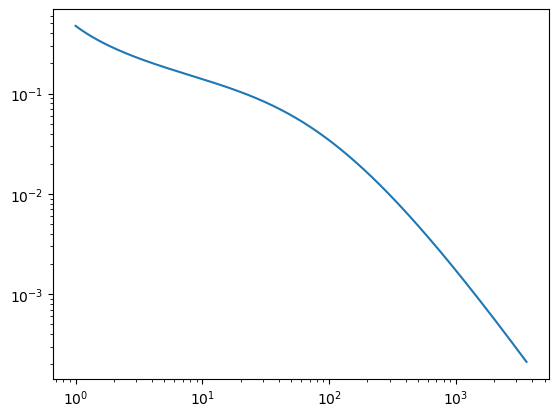

In [5]:
plt.plot(X,Y)
plt.xscale('log')
plt.yscale('log')

In [6]:
colossus_cosmology.setCosmology('planck18')
colossus_profile=profile_nfw.NFWProfile(M=Mhalo,c=conc,z=zhalo,mdef='200m')

In [35]:
def critical_surface_density(z_l, z_s, cosmo):
    """
    Calculates the critical surface density for gravitational lensing.

    Args:
        z_l (float): Redshift of the lensing galaxy.
        z_s (float): Redshift of the background source.
        cosmology (astropy.cosmology.Cosmology): The cosmological model to use.

    Returns:
        astropy.units.Quantity: The critical surface density.
    """
    # Define angular diameter distances
    D_l = cosmo.angular_diameter_distance(z_l)
    D_s = cosmo.angular_diameter_distance(z_s)
    D_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s)

    # Formula for the critical surface density
    numerator = (constants.c**2 * D_s)
    denominator = (4 * np.pi * constants.G * D_l * D_ls)
    sigma_crit = numerator / denominator

    # Convert to standard units for surface density (e.g., Msun / sq pc)
    return sigma_crit.to(u.M_sun / u.kpc**2)


# Define the redshifts for the lens and source
z_lens = 0.5   # Example lens redshift
z_source = 2.0 # Example source redshift

# Calculate the critical surface density
sigma_crit_value = critical_surface_density(z_lens, z_source, Planck18)

print(f"Lens redshift: {z_lens}")
print(f"Source redshift: {z_source}")
print(f"Critical surface density: {sigma_crit_value:.2f}")

# Example comparison: what if the lens is closer?
z_lens_closer = 0.25
sigma_crit_closer = critical_surface_density(z_lens_closer, z_source, Planck18)

print("\n--- Example with a closer lens ---")
print(f"Lens redshift: {z_lens_closer}")
print(f"Critical surface density: {sigma_crit_closer:.2f}")

Lens redshift: 0.5
Source redshift: 2.0
Critical surface density: 2023503616.23 solMass / kpc2

--- Example with a closer lens ---
Lens redshift: 0.25
Critical surface density: 2484122138.96 solMass / kpc2


In [44]:
integrate.quad?

Signature:
integrate.quad(
    func,
    a,
    b,
    args=(),
    full_output=0,
    epsabs=1.49e-08,
    epsrel=1.49e-08,
    limit=50,
    points=None,
    weight=None,
    wvar=None,
    wopts=None,
    maxp1=50,
    limlst=50,
    complex_func=False,
)
Docstring:
Compute a definite integral.

Integrate func from `a` to `b` (possibly infinite interval) using a
technique from the Fortran library QUADPACK.

Parameters
----------
func : {function, scipy.LowLevelCallable}
    A Python function or method to integrate. If `func` takes many
    arguments, it is integrated along the axis corresponding to the
    first argument.

    If the user desires improved integration performance, then `f` may
    be a `scipy.LowLevelCallable` with one of the signatures::

        double func(double x)
        double func(double x, void *user_data)
        double func(int n, double *xx)
        double func(int n, double *xx, void *user_data)

    The ``user_data`` is the data contained in the `scipy.

In [45]:
def gamma_nfw_colossus(colossus_profile,z_source,cosmo,r):
    z_lens = colossus_profile.z
    Sigma_crit = critical_surface_density(z_lens, z_source, cosmo).value

    Sigma_bar = (integrate.quad(colossus_profile.surfaceDensity,0.,r,epsrel=0.))[0]/r
    Sigma = colossus_profile.surfaceDensity(r)
    gamma = (Sigma_bar - Sigma)/Sigma_crit
    #print(Sigma_crit,Sigma_bar,Sigma)
    return gamma

In [48]:
radii = np.linspace(0.05,4,100)
gammas=[gamma_nfw_colossus(colossus_profile,1.5,Planck18,radius) for radius in radii]

/var/folders/d8/ryfw19n55wd0gghx8w6rw2400000gq/T/ipykernel_34539/3931640254.py:5: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  Sigma_bar = (integrate.quad(colossus_profile.surfaceDensity,0.,r,epsrel=0.))[0]/r


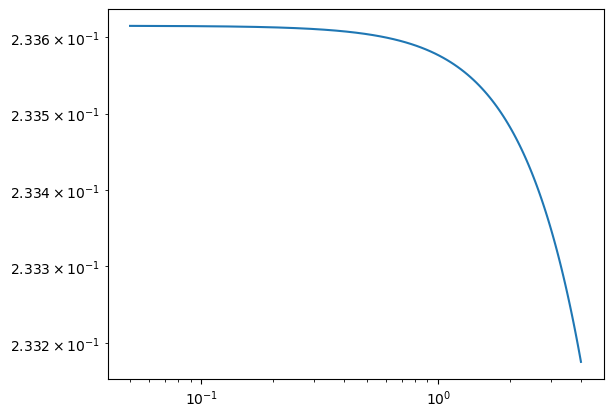

In [49]:
plt.plot(radii,gammas)
plt.xscale('log')
plt.yscale('log')

In [50]:
integrate.quad?

Signature:
integrate.quad(
    func,
    a,
    b,
    args=(),
    full_output=0,
    epsabs=1.49e-08,
    epsrel=1.49e-08,
    limit=50,
    points=None,
    weight=None,
    wvar=None,
    wopts=None,
    maxp1=50,
    limlst=50,
    complex_func=False,
)
Docstring:
Compute a definite integral.

Integrate func from `a` to `b` (possibly infinite interval) using a
technique from the Fortran library QUADPACK.

Parameters
----------
func : {function, scipy.LowLevelCallable}
    A Python function or method to integrate. If `func` takes many
    arguments, it is integrated along the axis corresponding to the
    first argument.

    If the user desires improved integration performance, then `f` may
    be a `scipy.LowLevelCallable` with one of the signatures::

        double func(double x)
        double func(double x, void *user_data)
        double func(int n, double *xx)
        double func(int n, double *xx, void *user_data)

    The ``user_data`` is the data contained in the `scipy.